**Changes in this version:** data leakage removed from the delay model (review_score, has_review_comment, seller_handling_days) and from delivery days (seller_handling_days); thresholds re-tuned; new v2 section at the end (2-3 leakage-free models per problem + review-text model). RandomForest is kept. Original code otherwise untouched.


## استدعاء المكتبات اللي هنشتغل بيها

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import numpy as np, pandas as pd
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, r2_score, mean_absolute_error, silhouette_score)

## تحميل ملف الداتا

In [2]:
df = pd.read_csv(r"D:\Olist_Ecommerce_Analysis\data\delivered_orders_df.csv")

## نبص على أول 8 صفوف

In [3]:
df.head(8)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_approval_days,actual_delivery_days,...,geolocation_lng,product_id,product_category_name,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_city,geolocation_state,distance_km
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0.007431,8.429144,...,-46.444311,87285b34884572647811a353c7ac498a,housewares,3504c0cb71d7fa48d967e0e4c94d59d9,9350.0,maua,SP,maua,SP,18.538322
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.279745,12.502292,...,-43.980818,595fac2a385ac33a80bd5114aec74eb8,perfumery,289cdb325fb7e7f891c38608bf9e0962,31570.0,belo horizonte,SP,belo horizonte,MG,849.520470
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0.011505,9.382708,...,-48.229588,aa4383b373c6aca5d8797843e5594415,auto,4869f7a5dfa277a7dca6462dcf3b52b2,14840.0,guariba,SP,guariba,SP,514.407596
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0.012419,13.196331,...,-43.923241,d0b61bfb1de832b15ba9d266ca96e5b0,pet_shop,66922902710d126a0e7d26b0e3805106,31842.0,belo horizonte,MG,belo horizonte,MG,1822.132331
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0.042940,2.830938,...,-46.262148,65266b2da20d04dbe00c5c2d3bb7859e,stationery,2c9e548be18521d1c43cde1c582c6de8,8752.0,mogi das cruzes,SP,mogi das cruzes,SP,29.765008
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01,0.009120,16.533125,...,-46.515649,060cb19345d90064d1015407193c233d,auto,8581055ce74af1daba164fdbd55a40de,7112.0,guarulhos,SP,guarulhos,SP,411.431740
6,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07,0.008113,9.981713,...,-46.553045,4520766ec412348b8d4caa5e8a18c464,auto,16090f2ca825584b5a147ab24aa30c86,12940.0,atibaia,SP,atibaia,SP,322.295460
7,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,1.348356,8.470405,...,-46.942793,ac1789e492dcd698c5c10b97a671243a,furniture_decor,63b9ae557efed31d1f7687917d248a8d,13720.0,sao jose do rio pardo,SP,são josé do rio pardo,SP,870.147680


## معلومات عن الأعمدة وأنواعها

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96478 entries, 0 to 96477
Data columns (total 49 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       96478 non-null  str    
 1   customer_id                    96478 non-null  str    
 2   order_status                   96478 non-null  str    
 3   order_purchase_timestamp       96478 non-null  str    
 4   order_approved_at              96478 non-null  str    
 5   order_delivered_carrier_date   96476 non-null  str    
 6   order_delivered_customer_date  96470 non-null  str    
 7   order_estimated_delivery_date  96478 non-null  str    
 8   payment_approval_days          96478 non-null  float64
 9   actual_delivery_days           96470 non-null  float64
 10  delivery_vs_estimated          96470 non-null  float64
 11  is_delayed                     96478 non-null  int64  
 12  seller_handling_days           96476 non-null  float64
 1

## نحوّل أعمدة التواريخ لصيغة تاريخ

In [5]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])

## نطلّع أعمدة جديدة من التاريخ (اليوم والساعة والشهر وأيام الوعد بالتوصيل)

In [6]:
df['purchase_dayofweek'] = df['order_purchase_timestamp'].dt.dayofweek
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour
df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['promised_delivery_days'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400.0

C:\Users\mahmo\AppData\Local\Temp\ipykernel_19484\2003096195.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['purchase_dayofweek'] = df['order_purchase_timestamp'].dt.dayofweek


## نتأكد إن الأعمدة الجديدة اتضافت

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96478 entries, 0 to 96477
Data columns (total 53 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96478 non-null  str           
 1   customer_id                    96478 non-null  str           
 2   order_status                   96478 non-null  str           
 3   order_purchase_timestamp       96478 non-null  datetime64[us]
 4   order_approved_at              96478 non-null  str           
 5   order_delivered_carrier_date   96476 non-null  str           
 6   order_delivered_customer_date  96470 non-null  str           
 7   order_estimated_delivery_date  96478 non-null  datetime64[us]
 8   payment_approval_days          96478 non-null  float64       
 9   actual_delivery_days           96470 non-null  float64       
 10  delivery_vs_estimated          96470 non-null  float64       
 11  is_delayed                

## نفصل الهدف (`is_delayed`) عن باقي الأعمدة

In [8]:
x = df.drop('is_delayed',axis=1)
y = df['is_delayed']

## نقسم الداتا تدريب واختبار (80% / 20%)

In [9]:
x_train,x_test,y_train,y_test = train_test_split(x,
                                                 y,
                                                 random_state=42,
                                                 test_size=0.2,
                                                 stratify=y)

## نشوف حجم كل جزء بعد التقسيم

In [10]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(77182, 52)
(19296, 52)
(77182,)
(19296,)


## نعدّ القيم الفاضية في كل عمود

In [11]:
x_train.isna().sum().sort_values(ascending=False)


product_photos_qty               1067
review_answer_timestamp           511
review_score                      511
review_creation_date              511
review_response_delay_days        511
shipping_transit_days               8
order_delivered_customer_date       7
actual_delivery_days                7
delivery_vs_estimated               7
seller_handling_days                2
order_delivered_carrier_date        2
customer_id                         0
payment_approval_days               0
customer_unique_id                  0
customer_zip_code_prefix            0
order_id                            0
order_purchase_timestamp            0
order_status                        0
order_estimated_delivery_date       0
order_approved_at                   0
total_payment_value                 0
customer_lng                        0
customer_lat                        0
customer_state                      0
customer_city                       0
payment_type                        0
payment_inst

## نملى القيم الفاضية (الوسيط للأرقام والأكتر تكرارًا للنصوص)

In [12]:
from sklearn.impute import SimpleImputer

num_cols = x_train.select_dtypes(include='number').columns
cat_cols = x_train.select_dtypes(exclude='number').columns

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

x_train[num_cols] = num_imputer.fit_transform(x_train[num_cols])
x_test[num_cols] = num_imputer.transform(x_test[num_cols])

x_train[cat_cols] = cat_imputer.fit_transform(x_train[cat_cols])
x_test[cat_cols] = cat_imputer.transform(x_test[cat_cols])

## نتأكد إن مفيش قيم فاضية فضلت في التدريب

In [13]:
x_train.isna().sum().sort_values(ascending=False)

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
payment_approval_days            0
actual_delivery_days             0
delivery_vs_estimated            0
seller_handling_days             0
shipping_transit_days            0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
customer_lat                     0
customer_lng                     0
total_payment_value              0
payment_installments_max         0
num_payments                     0
payment_type                     0
review_score                     0
review_comment_message           0
review_response_delay_days       0
review_creation_date             0
review_answer_timestamp          0
has_review_comment  

## نحوّل الأعمدة النصية (الولايات ونوع الدفع) لأعمدة 0 و1 (One-Hot)

In [14]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd


oh = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

cat_cols = [
    'order_status',
    'payment_type',
    'customer_state',
    'seller_state'
]


train_encoded = oh.fit_transform(x_train[cat_cols])
test_encoded = oh.transform(x_test[cat_cols])


encoded_cols = oh.get_feature_names_out(cat_cols)
train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_cols, index=x_train.index)
test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_cols, index=x_test.index)


x_train = x_train.drop(columns=cat_cols).join(train_encoded_df)
x_test = x_test.drop(columns=cat_cols).join(test_encoded_df)

## نشيل أعمدة الـ ID لأنها مالهاش لازمة في التدريب

In [15]:
id_cols = [
    'order_id',
    'customer_id',
    'customer_unique_id',
    'product_id',
    'seller_id'
]

x_train.drop(columns=id_cols, inplace=True, errors='ignore')
x_test.drop(columns=id_cols, inplace=True, errors='ignore')

C:\Users\mahmo\AppData\Local\Temp\ipykernel_19484\1776965610.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  x_train.drop(columns=id_cols, inplace=True, errors='ignore')
C:\Users\mahmo\AppData\Local\Temp\ipykernel_19484\1776965610.py:10: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  x_test.drop(columns=id_cols, inplace=True, errors='ignore')


## نحوّل المدن والفئات لأرقام حسب عدد تكرارها (Count Encoding)

In [16]:
import category_encoders as ce

freq_cols = [
    'customer_city',
    'seller_city',
    'product_category_name'
]

encoder = ce.CountEncoder(cols=freq_cols)

x_train[freq_cols] = encoder.fit_transform(x_train[freq_cols])
x_test[freq_cols] = encoder.transform(x_test[freq_cols])

## نعمل Scaling للأرقام عشان تبقى في نفس المقياس

In [17]:
from sklearn.preprocessing import RobustScaler
import numpy as np


numeric_cols = x_train.select_dtypes(include=[np.number]).columns

scaler = RobustScaler()


x_train[numeric_cols] = scaler.fit_transform(x_train[numeric_cols])
x_test[numeric_cols] = scaler.transform(x_test[numeric_cols])


x_train = x_train[numeric_cols]
x_test = x_test[numeric_cols]

## استدعاء موديلات التصنيف ومقاييس التقييم

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

## نختار الأعمدة اللي هندرّب بيها موديل التأخير

In [ ]:
# DATA LEAKAGE FIX: review_score, has_review_comment and seller_handling_days are only known AFTER the order,
# so they were removed from the delay features.
features = [
    'num_unique_sellers',
    'purchase_month',
    'customer_lng',
    'num_payments',
    'customer_lat',
    'total_items',
    'geolocation_lat',
    'geolocation_lng',
    'total_payment_value',
    'promised_delivery_days',
    'price',
    'product_volume_m3',
    'product_photos_qty',
    'freight_value',
    'distance_km',
    'purchase_dayofweek',
    'product_weight_kg',
    'payment_approval_days',
    'payment_installments_max'
]

# Dynamically add the one-hot encoded columns that replaced the original categorical columns
encoded_features = []
for cat_col in ['seller_state', 'customer_state', 'payment_type']:
    encoded_features.extend([col for col in x_train.columns if col.startswith(cat_col + '_')])

final_features = features + encoded_features

x_train_fet = x_train[final_features]
x_test_fet = x_test[final_features]

## موديل 1 للتأخير: HistGradientBoosting (تدريب)

In [20]:
boosting_model = HistGradientBoostingClassifier(
            max_iter=500,
            learning_rate=0.05,
            max_leaf_nodes=63,
            min_samples_leaf=30,
            l2_regularization=1.0,
            class_weight="balanced",
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=25,
            random_state=42,
        )


boosting_model.fit(x_train_fet, y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",500
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",63
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",30
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",True
,"n_iter_no_change n_iter_no_change: int, default=10Used to determine when to ""early stop"". The fitting process isstopped when none of the last ``n_iter_no_change`` scores are betterthan the ``n_iter_no_change - 1`` -th-to-last one, up to sometolerance. Only used if early stopping is performed.",25
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None


## تقييم HistGradientBoosting على بيانات الاختبار

In [ ]:
y_prob = boosting_model.predict_proba(x_test_fet)[:, 1]
threshold = 0.63   # re-tuned for the leakage-free features (best F1 on a validation split of the training data)
y_pred = (y_prob >= threshold).astype(int)
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

## موديل 2 للتأخير: Random Forest (تدريب)

In [22]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(x_train_fet, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

## تقييم Random Forest

In [ ]:
y_prob = rf_model.predict_proba(x_test_fet)[:, 1]
threshold = 0.16   # re-tuned for the leakage-free features (best F1 on a validation split of the training data)
y_pred_r = (y_prob >= threshold).astype(int)
print("Precision:", round(precision_score(y_test, y_pred_r), 4))
print("Recall:", round(recall_score(y_test, y_pred_r), 4))
print("F1:", round(f1_score(y_test, y_pred_r), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_r))
print("\nClassification Report:\n", classification_report(y_test, y_pred_r))

## موديل 3 للتأخير: XGBoost (تدريب)

In [24]:
from xgboost import XGBClassifier
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.08,
    max_depth=7,
    scale_pos_weight=scale_pos_weight,
    enable_categorical=True,
    eval_metric="auc",
    random_state=42,
    n_jobs=-1,
)

model.fit(x_train_fet, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## تقييم XGBoost

In [ ]:
y_pred = model.predict(x_test_fet)
y_proba = model.predict_proba(x_test_fet)[:, 1]
threshold = 0.62   # re-tuned for the leakage-free features (best F1 on a validation split of the training data)
y_pred = (y_proba >= threshold).astype(int)


print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

## MLflow للمشكلة 1 (توقع التأخير)
الخلايا الجديدة دي بتسجّل الموديلات التلاتة (HistGradientBoosting / Random Forest / XGBoost) في MLflow: البارامترات والمقاييس ورسمة الـ Confusion Matrix والموديل نفسه. وكمان بتحفظ كل خطوات الـ preprocessing في فولدر `artifacts/` عشان تطبيق Streamlit يستخدمهم.
بعد التشغيل: `mlflow ui --backend-store-uri sqlite:///mlflow.db`


In [ ]:
# ===== MLflow: الإعداد =====
# pip install mlflow joblib   (لو مش متسطبين)
import os, json, joblib
import mlflow, mlflow.sklearn, mlflow.xgboost
from mlflow.models import infer_signature
from sklearn.metrics import average_precision_score

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("olist_delay_prediction")

ART_DIR = "artifacts"
os.makedirs(ART_DIR, exist_ok=True)


In [ ]:
# ===== MLflow: دالة تسجيل أي موديل تأخير =====
def log_delay_model(run_name, model, threshold, flavor="sklearn"):
    y_prob_ = model.predict_proba(x_test_fet)[:, 1]
    y_pred_ = (y_prob_ >= threshold).astype(int)

    with mlflow.start_run(run_name=run_name) as run:
        # البارامترات
        mlflow.log_params({k: str(v) for k, v in model.get_params().items()})
        mlflow.log_param("threshold", threshold)
        mlflow.log_param("n_features", x_train_fet.shape[1])
        mlflow.set_tag("problem", "delivery_delay")

        # المقاييس (نفس طريقة التقييم اللي في النوتبوك)
        mlflow.log_metrics({
            "precision": precision_score(y_test, y_pred_),
            "recall": recall_score(y_test, y_pred_),
            "f1": f1_score(y_test, y_pred_),
            "roc_auc": roc_auc_score(y_test, y_prob_),
            "pr_auc": average_precision_score(y_test, y_prob_),
        })

        # رسمة Confusion Matrix
        fig, ax = plt.subplots(figsize=(4, 4))
        ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_)).plot(ax=ax, colorbar=False)
        ax.set_title(f"{run_name} (threshold={threshold})")
        mlflow.log_figure(fig, "confusion_matrix.png")
        plt.close(fig)

        # الموديل نفسه
        example = x_test_fet.head(5)
        sig = infer_signature(example, y_prob_[:5])
        if flavor == "xgboost":
            mlflow.xgboost.log_model(model, "model", signature=sig, input_example=example)
        else:
            mlflow.sklearn.log_model(model, "model", signature=sig, input_example=example,
                                     serialization_format="cloudpickle")

        print(f"{run_name}: run_id={run.info.run_id}  F1={f1_score(y_test, y_pred_):.4f}  ROC-AUC={roc_auc_score(y_test, y_prob_):.4f}")
        return run.info.run_id


In [ ]:
# ===== MLflow: تسجيل الموديلات التلاتة =====
# (الـ thresholds الجديدة بعد إصلاح الـ leakage: 0.63 / 0.16 / 0.62)
DELAY_THRESHOLDS = {"HistGradientBoosting": 0.63, "RandomForest": 0.16, "XGBoost": 0.62}

run_hgb = log_delay_model("HistGradientBoosting", boosting_model, DELAY_THRESHOLDS["HistGradientBoosting"])
run_rf  = log_delay_model("RandomForest",         rf_model,       DELAY_THRESHOLDS["RandomForest"])
run_xgb = log_delay_model("XGBoost",              model,          DELAY_THRESHOLDS["XGBoost"], flavor="xgboost")


In [ ]:
# ===== حفظ كل اللي تطبيق Streamlit محتاجه (preprocessing + الموديلات) =====
raw_template = x.iloc[[0]].copy()          # صف خام واحد بنفس الأعمدة والأنواع
bundle = {
    "num_imputer": num_imputer,
    "oh": oh,
    "ohe_cols": ['order_status', 'payment_type', 'customer_state', 'seller_state'],
    "count_encoder": encoder,
    "freq_cols": ['customer_city', 'seller_city', 'product_category_name'],
    "id_cols": id_cols,
    "scaler": scaler,
    "final_features": final_features,
    "thresholds": DELAY_THRESHOLDS,
    "raw_template": raw_template,
    "options": {
        "customer_state": sorted(df["customer_state"].dropna().unique().tolist()),
        "seller_state": sorted(df["seller_state"].dropna().unique().tolist()),
        "payment_type": sorted(df["payment_type"].dropna().unique().tolist()),
    },
    # قيم افتراضية للمدخلات الرقمية (الوسيط) عشان واجهة التطبيق
    "defaults": df[[c for c in features if c in df.columns]].median(numeric_only=True).to_dict(),
}
joblib.dump(bundle, f"{ART_DIR}/preprocess.joblib")
joblib.dump(boosting_model, f"{ART_DIR}/HistGradientBoosting.joblib")
joblib.dump(rf_model,       f"{ART_DIR}/RandomForest.joblib")
joblib.dump(model,          f"{ART_DIR}/XGBoost.joblib")

# نسجّل الفولدر ده برضه في MLflow كـ run مستقل
with mlflow.start_run(run_name="app_artifacts"):
    mlflow.log_artifacts(ART_DIR, artifact_path="app_artifacts")
    mlflow.set_tag("problem", "delivery_delay")
print("تم الحفظ في:", os.path.abspath(ART_DIR))


## MLflow: أدوات مشتركة للمشاكل من 2 لـ 5
لازم تشغل الخلية دي قبل خلايا MLflow بتاعة المشاكل 2 و3 و4 و5. وبتحفظ معلومات إضافية في `artifacts/` للتطبيق.

In [ ]:
# ===== MLflow: أدوات مشتركة لباقي المشاكل (2 و3 و4 و5) =====
from sklearn.metrics import mean_squared_error, ConfusionMatrixDisplay
from sklearn.decomposition import PCA

def _unscale(values, col):
    i = list(numeric_cols).index(col)
    return np.asarray(values) * scaler.scale_[i] + scaler.center_[i]


def log_regression(experiment, run_name, model, cols, target, problem):
    """تسجيل موديل Regression (تكلفة الشحن / أيام التوصيل) في MLflow"""
    mlflow.set_experiment(experiment)
    X, y_s = x_test[cols], x_test[target]
    p_s = model.predict(X)
    y_true, y_hat = _unscale(y_s, target), _unscale(p_s, target)
    metrics = {
        "r2": r2_score(y_s, p_s),
        "mae": mean_absolute_error(y_true, y_hat),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_hat))),
    }
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({k: str(v) for k, v in model.get_params().items()})
        mlflow.log_param("n_features", len(cols))
        mlflow.log_param("features", ", ".join(cols)[:500])
        mlflow.set_tag("problem", problem)
        mlflow.log_metrics(metrics)

        idx = np.random.RandomState(42).choice(len(y_true), min(3000, len(y_true)), replace=False)
        fig, ax = plt.subplots(figsize=(4.5, 4.5))
        ax.scatter(y_true[idx], y_hat[idx], s=5, alpha=0.4)
        lim = [min(y_true.min(), y_hat.min()), max(y_true.max(), y_hat.max())]
        ax.plot(lim, lim, "r--", lw=1)
        ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.set_title(f"{run_name}: actual vs predicted")
        mlflow.log_figure(fig, "actual_vs_predicted.png")
        plt.close(fig)

        mlflow.sklearn.log_model(model, "model",
                                 signature=infer_signature(X.head(5), p_s[:5]),
                                 input_example=X.head(5), serialization_format="cloudpickle")
    print(f"{run_name}: R2={metrics['r2']:.4f}  MAE={metrics['mae']:.4f}  RMSE={metrics['rmse']:.4f}  run_id={run.info.run_id}")
    return run.info.run_id


def log_classifier(experiment, run_name, model, X, y, threshold, problem):
    """تسجيل موديل تصنيف (رضا العميل) في MLflow"""
    mlflow.set_experiment(experiment)
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= threshold).astype(int)
    metrics = {
        "precision": precision_score(y, pred), "recall": recall_score(y, pred),
        "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob),
        "pr_auc": average_precision_score(y, prob),
    }
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({k: str(v) for k, v in model.get_params().items()})
        mlflow.log_param("threshold", float(threshold))
        mlflow.log_param("n_features", X.shape[1])
        mlflow.set_tag("problem", problem)
        mlflow.log_metrics(metrics)
        fig, ax = plt.subplots(figsize=(4, 4))
        ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot(ax=ax, colorbar=False)
        ax.set_title(f"{run_name} (threshold={threshold:.3f})")
        mlflow.log_figure(fig, "confusion_matrix.png")
        plt.close(fig)
        mlflow.sklearn.log_model(model, "model",
                                 signature=infer_signature(X.head(5), prob[:5]),
                                 input_example=X.head(5), serialization_format="cloudpickle")
    print(f"{run_name}: F1={metrics['f1']:.4f}  ROC-AUC={metrics['roc_auc']:.4f}  run_id={run.info.run_id}")
    return run.info.run_id


# ----- معلومات إضافية يحتاجها تطبيق Streamlit للمشاكل التانية -----
_d = df[["actual_delivery_days", "promised_delivery_days", "delivery_vs_estimated"]].dropna()
_slope, _intercept = np.polyfit(_d["actual_delivery_days"] - _d["promised_delivery_days"], _d["delivery_vs_estimated"], 1)
APP_EXTRA = {
    "defaults": df.median(numeric_only=True).to_dict(),
    "categories": sorted(df["product_category_name"].dropna().unique().tolist()),
    "customer_cities": df["customer_city"].value_counts().head(300).index.tolist(),
    "seller_cities": df["seller_city"].value_counts().head(300).index.tolist(),
    # delivery_vs_estimated ~= slope * (actual_delivery_days - promised_delivery_days) + intercept
    "dve_fit": (float(_slope), float(_intercept)),
}
joblib.dump(APP_EXTRA, f"{ART_DIR}/app_extra.joblib")
print("جاهز. delivery_vs_estimated =", round(_slope, 3), "* (actual - promised) +", round(_intercept, 3))

## المشكلة 2 (تكلفة الشحن): نختار الأعمدة

In [26]:
feature_cost = [
    "product_volume_m3",
    "product_weight_kg",
    "total_items",
    "distance_km",
    "price",
    "seller_zip_code_prefix",
    "purchase_month",
    "purchase_dayofweek",
    "purchase_hour",
    "customer_lat",
    "customer_lng",
    "geolocation_lat",
    "geolocation_lng",
    "promised_delivery_days"
]

## نضيف أعمدة ولاية العميل للأعمدة المختارة

In [27]:
for c in x_train.columns:
    if c.startswith("customer_state_"):
        feature_cost.append(c)


## نشوف القايمة النهائية للأعمدة

In [28]:
feature_cost

['product_volume_m3',
 'product_weight_kg',
 'total_items',
 'distance_km',
 'price',
 'seller_zip_code_prefix',
 'purchase_month',
 'purchase_dayofweek',
 'purchase_hour',
 'customer_lat',
 'customer_lng',
 'geolocation_lat',
 'geolocation_lng',
 'promised_delivery_days',
 'customer_state_AC',
 'customer_state_AL',
 'customer_state_AM',
 'customer_state_AP',
 'customer_state_BA',
 'customer_state_CE',
 'customer_state_DF',
 'customer_state_ES',
 'customer_state_GO',
 'customer_state_MA',
 'customer_state_MG',
 'customer_state_MS',
 'customer_state_MT',
 'customer_state_PA',
 'customer_state_PB',
 'customer_state_PE',
 'customer_state_PI',
 'customer_state_PR',
 'customer_state_RJ',
 'customer_state_RN',
 'customer_state_RO',
 'customer_state_RR',
 'customer_state_RS',
 'customer_state_SC',
 'customer_state_SE',
 'customer_state_SP',
 'customer_state_TO']

## نجرّب Random Forest لتوقع تكلفة الشحن (تدريب)

In [29]:
rf_freight = RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=3,
                                   random_state=42, n_jobs=-1)
rf_freight.fit(x_train[feature_cost], x_train["freight_value"])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## تقييم توقع تكلفة الشحن (R² وMAE)

In [30]:
i = list(numeric_cols).index("freight_value")

y_true = x_test["freight_value"] * scaler.scale_[i] + scaler.center_[i]
y_pred = rf_freight.predict(x_test[feature_cost]) * scaler.scale_[i] + scaler.center_[i]

print("R2:", round(r2_score(x_test["freight_value"], rf_freight.predict(x_test[feature_cost])), 4))
print("MAE:", round(mean_absolute_error(y_true, y_pred), 4))

R2: 0.7078
MAE: 3.6929


## MLflow للمشكلة 2 (تكلفة الشحن)

In [ ]:
# ===== MLflow: المشكلة 2 (تكلفة الشحن) =====
log_regression("olist_freight_cost", "RandomForest_freight", rf_freight, feature_cost,
               "freight_value", "freight_cost")
joblib.dump({"model": rf_freight, "cols": feature_cost, "target": "freight_value"}, f"{ART_DIR}/freight.joblib")

## المشكلة 3 (أيام التوصيل): نختار الأعمدة

In [ ]:
# seller_handling_days removed (data leakage: only known after the order)
f3_cols = ["order_purchase_timestamp", "distance_km", "order_estimated_delivery_date",
           "customer_lat", "customer_zip_code_prefix", "customer_lng", "purchase_month",
           "promised_delivery_days"]
f3_cols += [c for c in x_train.columns if c.startswith("customer_state_")]
f3_cols = [c for c in f3_cols if c in x_train.columns]

## نجرّب Random Forest لتوقع أيام التوصيل (تدريب)

In [32]:
rf_days = RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=3,
                                random_state=42, n_jobs=-1)
rf_days.fit(x_train[f3_cols], x_train["actual_delivery_days"])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## تقييم توقع أيام التوصيل (R² وMAE)

In [33]:
i = list(numeric_cols).index("actual_delivery_days")
pred = rf_days.predict(x_test[f3_cols])
y_true = x_test["actual_delivery_days"] * scaler.scale_[i] + scaler.center_[i]
y_hat = pred * scaler.scale_[i] + scaler.center_[i]

print("R2:", round(r2_score(x_test["actual_delivery_days"], pred), 4))
print("MAE :", round(mean_absolute_error(y_true, y_hat), 4))

R2: 0.4361
MAE : 4.0648


## MLflow للمشكلة 3 (أيام التوصيل)

In [ ]:
# ===== MLflow: المشكلة 3 (أيام التوصيل) =====
log_regression("olist_delivery_days", "RandomForest_days", rf_days, f3_cols,
               "actual_delivery_days", "delivery_days")
joblib.dump({"model": rf_days, "cols": f3_cols, "target": "actual_delivery_days"}, f"{ART_DIR}/delivery_days.joblib")

## المشكلة 4 (رضا العميل): نجهّز الأعمدة ونحدد مين غير راضي

In [34]:
f4_cols = [
    "delivery_vs_estimated",
    "total_items",
    "actual_delivery_days",
    "num_unique_sellers",
    "product_category_name",
    "purchase_month",
    "seller_zip_code_prefix",
    "customer_city",
    "product_volume_m3",
    "promised_delivery_days"
]
i = list(numeric_cols).index("review_score")
unsat_train = (np.round(x_train["review_score"] * scaler.scale_[i] + scaler.center_[i]) <= 3).astype(int)
unsat_test = (np.round(x_test["review_score"] * scaler.scale_[i] + scaler.center_[i]) <= 3).astype(int)

x4_tr, x4_val, y4_tr, y4_val = train_test_split(x_train[f4_cols], unsat_train, test_size=0.2,
                                                stratify=unsat_train, random_state=42)

## موديل رضا العميل: HistGradientBoosting (تدريب)

In [35]:
boosting_review = HistGradientBoostingClassifier(
            max_iter=500,
            learning_rate=0.05,
            max_leaf_nodes=63,
            min_samples_leaf=30,
            l2_regularization=1.0,
            class_weight="balanced",
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=25,
            random_state=42,
        )

boosting_review.fit(x4_tr, y4_tr)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",500
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",63
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",30
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",True
,"n_iter_no_change n_iter_no_change: int, default=10Used to determine when to ""early stop"". The fitting process isstopped when none of the last ``n_iter_no_change`` scores are betterthan the ``n_iter_no_change - 1`` -th-to-last one, up to sometolerance. Only used if early stopping is performed.",25
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None


## تقييم موديل رضا العميل

In [36]:
p, r, t = precision_recall_curve(y4_val, boosting_review.predict_proba(x4_val)[:, 1])
threshold = t[(2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)).argmax()]

y_prob = boosting_review.predict_proba(x_test[f4_cols])[:, 1]
y_pred = (y_prob >= threshold).astype(int)
print("Threshold:", round(threshold, 3))
print("Precision:", round(precision_score(unsat_test, y_pred), 4))
print("Recall:", round(recall_score(unsat_test, y_pred), 4))
print("F1:", round(f1_score(unsat_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(unsat_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(unsat_test, y_prob), 4))
print("\nConfusion Matrix:\n", confusion_matrix(unsat_test, y_pred))

Threshold: 0.528
Precision: 0.4611
Recall: 0.4465
F1: 0.4537
ROC-AUC: 0.7145
PR-AUC: 0.5038

Confusion Matrix:
 [[13137  2112]
 [ 2240  1807]]


## MLflow للمشكلة 4 (رضا العميل)

In [ ]:
# ===== MLflow: المشكلة 4 (رضا العميل) =====
# نفس طريقة اختيار الـ threshold اللي فوق (أفضل F1 على بيانات الـ validation)
_p, _r, _t = precision_recall_curve(y4_val, boosting_review.predict_proba(x4_val)[:, 1])
sat_threshold = float(_t[(2 * _p[:-1] * _r[:-1] / (_p[:-1] + _r[:-1] + 1e-9)).argmax()])

log_classifier("olist_customer_satisfaction", "HistGradientBoosting_review", boosting_review,
               x_test[f4_cols], unsat_test, sat_threshold, "customer_satisfaction")
joblib.dump({"model": boosting_review, "cols": f4_cols, "threshold": sat_threshold}, f"{ART_DIR}/satisfaction.joblib")

## المشكلة 5 (تقسيم العملاء): نجهّز الداتا ونختار عدد الشرايح

In [37]:
f5_cols = ["total_payment_value", "total_items", "price", "freight_value", "payment_installments_max",
           "num_payments", "product_category_name", "purchase_month"]
f5_cols += [c for c in x_train.columns if c.startswith(("payment_type_", "customer_state_"))]

Z = pd.concat([x_train[f5_cols], x_test[f5_cols]]).clip(-5, 5)
sample = Z.sample(10000, random_state=42)

for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(sample)
    print(k, round(silhouette_score(sample, labels), 3))

2 0.475
3 0.295
4 0.236
5 0.197
6 0.161
7 0.161
8 0.162


## نطبّق K-Means ونشوف مواصفات كل شريحة

In [38]:
kmeans_model = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans_model.fit(Z)

Z["cluster"] = kmeans_model.labels_
print(Z["cluster"].value_counts(normalize=True).round(3))

for c in ["total_payment_value", "total_items", "price", "freight_value"]:
    i = list(numeric_cols).index(c)
    print(c, (Z.groupby("cluster")[c].mean() * scaler.scale_[i] + scaler.center_[i]).round(2).to_dict())

cluster
0    0.849
1    0.151
Name: proportion, dtype: float64
total_payment_value {0: 103.17, 1: 398.62}
total_items {0: 1.08, 1: 1.5}
price {0: 85.34, 1: 347.19}
freight_value {0: 17.81, 1: 42.9}


## نرسم الشرايح بالـ PCA ومتوسط كل شريحة

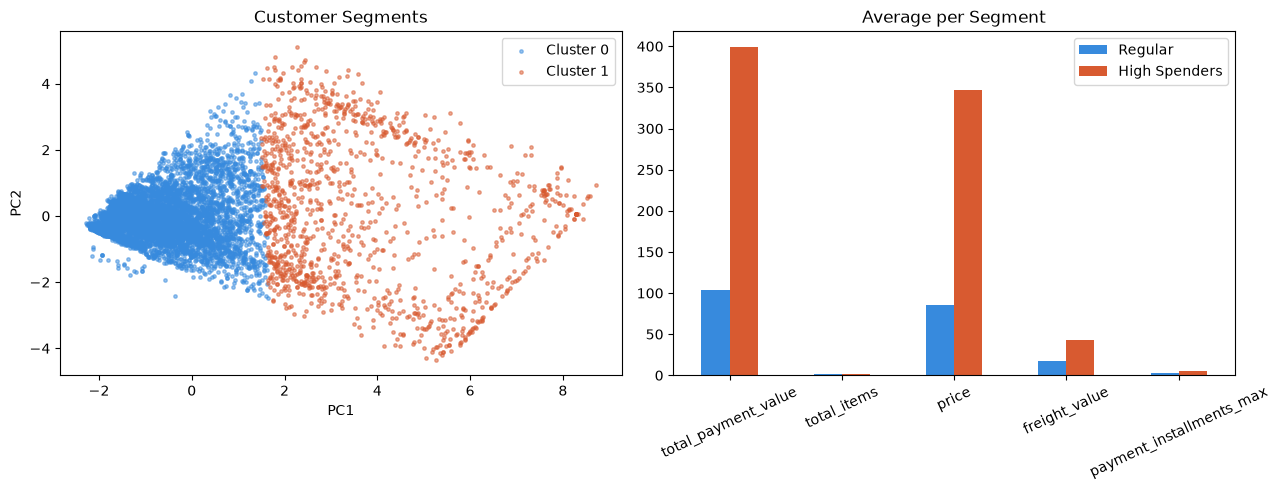

In [39]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np


pca = PCA(n_components=2)
pcs = pca.fit_transform(Z[f5_cols])

# اختيار 8000 عينة عشوائية
sample = np.random.choice(len(Z), 8000, replace=False)


colors = ['#378ADD', '#D85A30']


plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)

for cluster in [0, 1]:
    mask = Z["cluster"].values[sample] == cluster

    plt.scatter(
        pcs[sample][mask, 0],
        pcs[sample][mask, 1],
        color=colors[cluster],
        label=f"Cluster {cluster}",
        alpha=0.5,
        s=6
    )

plt.title("Customer Segments")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()



plt.subplot(1, 2, 2)

features = [
    "total_payment_value",
    "total_items",
    "price",
    "freight_value",
    "payment_installments_max"
]

profile = Z.groupby("cluster")[features].mean()

for col in features:
    i = list(numeric_cols).index(col)
    profile[col] = profile[col] * scaler.scale_[i] + scaler.center_[i]

profile.T.plot(
    kind="bar",
    ax=plt.gca(),
    color=colors
)

plt.title("Average per Segment")
plt.xticks(rotation=25)
plt.legend(["Regular", "High Spenders"])

plt.tight_layout()
plt.show()


## MLflow للمشكلة 5 (تقسيم العملاء)
بتسجّل موديل K-Means (البارامترات + silhouette + حجم كل شريحة + رسمة PCA) وبتحفظ الموديل لتطبيق Streamlit.

In [ ]:
# ===== MLflow: المشكلة 5 (تقسيم العملاء) =====
mlflow.set_experiment("olist_customer_segments")

pca5 = PCA(n_components=2, random_state=42).fit(Z[f5_cols])
pcs5 = pca5.transform(Z[f5_cols])

# اسم كل شريحة: اللي متوسط دفعها أعلى = High Spenders
spend_i = list(f5_cols).index("total_payment_value")
hi = int(np.argmax(kmeans_model.cluster_centers_[:, spend_i]))
cluster_names = {c: ("High Spenders" if c == hi else "Regular") for c in range(kmeans_model.n_clusters)}

prof_cols = ["total_payment_value", "total_items", "price", "freight_value", "payment_installments_max"]
profile5 = Z.groupby("cluster")[prof_cols].mean()
for c in prof_cols:
    profile5[c] = _unscale(profile5[c], c)
sizes5 = Z["cluster"].value_counts(normalize=True).sort_index()

_samp = Z[f5_cols].sample(min(10000, len(Z)), random_state=42)
sil = silhouette_score(_samp, kmeans_model.predict(_samp))

with mlflow.start_run(run_name="KMeans_segments") as run:
    mlflow.log_params({k: str(v) for k, v in kmeans_model.get_params().items()})
    mlflow.log_param("n_features", len(f5_cols))
    mlflow.set_tag("problem", "customer_segments")
    mlflow.log_metrics({"inertia": float(kmeans_model.inertia_), "silhouette": float(sil)})
    for c, share in sizes5.items():
        mlflow.log_metric(f"share_cluster_{c}_{cluster_names[c].replace(' ', '_')}", float(share))
    mlflow.log_dict({"names": {str(k): v for k, v in cluster_names.items()},
                     "avg_per_segment": profile5.round(2).to_dict()}, "segments_profile.json")

    idx = np.random.RandomState(42).choice(len(Z), min(6000, len(Z)), replace=False)
    fig, ax = plt.subplots(figsize=(5, 4))
    for c in range(kmeans_model.n_clusters):
        m = Z["cluster"].values[idx] == c
        ax.scatter(pcs5[idx][m, 0], pcs5[idx][m, 1], s=5, alpha=0.4, label=cluster_names[c])
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("Customer segments (PCA)")
    mlflow.log_figure(fig, "segments_pca.png")
    plt.close(fig)

    mlflow.sklearn.log_model(kmeans_model, "model",
                             signature=infer_signature(Z[f5_cols].head(5), kmeans_model.labels_[:5]),
                             input_example=Z[f5_cols].head(5), serialization_format="cloudpickle")
print("KMeans_segments: silhouette =", round(sil, 3), " run_id =", run.info.run_id)

_bg = np.random.RandomState(0).choice(len(Z), min(3000, len(Z)), replace=False)
joblib.dump({
    "model": kmeans_model, "pca": pca5, "cols": f5_cols, "names": cluster_names,
    "profile": profile5.to_dict(), "sizes": sizes5.to_dict(),
    "bg_pcs": pcs5[_bg], "bg_cluster": Z["cluster"].values[_bg],
}, f"{ART_DIR}/segments.joblib")
print("تم حفظ كل موديلات التطبيق في:", os.path.abspath(ART_DIR))

In [51]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([
    Dense(64, activation='relu', input_shape=(x_train_fet.shape[1],)),
    Dropout(0.2),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

c:\Users\mahmo\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [52]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [53]:
history = model.fit(
    x_train_fet,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32
)

Epoch 1/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9248 - loss: 0.2254 - val_accuracy: 0.9317 - val_loss: 0.1946
Epoch 2/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9308 - loss: 0.2000 - val_accuracy: 0.9344 - val_loss: 0.1888
Epoch 3/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9328 - loss: 0.1942 - val_accuracy: 0.9348 - val_loss: 0.1874
Epoch 4/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9346 - loss: 0.1893 - val_accuracy: 0.9367 - val_loss: 0.1836
Epoch 5/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9353 - loss: 0.1867 - val_accuracy: 0.9352 - val_loss: 0.1849
Epoch 6/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9363 - loss: 0.1845 - val_accuracy: 0.9377 - val_loss: 0.1809
Epoch 7/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9370 - loss: 0.1822 - val_accuracy: 0.9387 - val_loss: 0.1795
Epoch 8/50
1930/1930 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9379 - loss: 0.1809 - 

In [55]:
loss, accuracy = model.evaluate(x_test_fet, y_test)

print("Loss:", loss)
print("Accuracy:", accuracy)

603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 707us/step - accuracy: 0.9388 - loss: 0.1797
Loss: 0.17969749867916107
Accuracy: 0.9387956261634827


In [ ]:
y_pred = (y_pred > 0.5).astype(int)

603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 451us/step


In [57]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = (model.predict(x_test_fet) > 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, model.predict(x_test_fet)))

603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step
[[17481   250]
 [  931   634]]
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     17731
           1       0.72      0.41      0.52      1565

    accuracy                           0.94     19296
   macro avg       0.83      0.70      0.74     19296
weighted avg       0.93      0.94      0.93     19296

603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step
ROC-AUC: 0.8857796934413709


In [58]:
train_loss, train_acc = model.evaluate(x_train_fet, y_train)
test_loss, test_acc = model.evaluate(x_test_fet, y_test)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)

2412/2412 ━━━━━━━━━━━━━━━━━━━━ 2s 685us/step - accuracy: 0.9471 - loss: 0.1548
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 700us/step - accuracy: 0.9388 - loss: 0.1797
Train Accuracy: 0.9470990896224976
Test Accuracy: 0.9387956261634827


In [59]:
from sklearn.metrics import classification_report

y_prob = model.predict(x_test_fet).ravel()

for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(classification_report(y_test, y_pred))

603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step

Threshold: 0.5
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     17731
           1       0.72      0.41      0.52      1565

    accuracy                           0.94     19296
   macro avg       0.83      0.70      0.74     19296
weighted avg       0.93      0.94      0.93     19296


Threshold: 0.4
              precision    recall  f1-score   support

           0       0.95      0.98      0.97     17731
           1       0.67      0.47      0.55      1565

    accuracy                           0.94     19296
   macro avg       0.81      0.72      0.76     19296
weighted avg       0.93      0.94      0.93     19296


Threshold: 0.3
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     17731
           1       0.59      0.53      0.56      1565

    accuracy                           0.93     19296
   macro avg       0.77      0.75    

In [61]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    x_train_fet, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

In [63]:
import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix

# 1. Predictions on Validation
y_val_prob = model.predict(X_val).ravel()

# 2. Find best threshold using F1
precision, recall, thresholds = precision_recall_curve(y_val, y_val_prob)

f1 = 2 * (precision * recall) / (precision + recall + 1e-8)

best_idx = np.argmax(f1[:-1])
best_threshold = thresholds[best_idx]

print("Best Threshold:", best_threshold)
print("Best Validation F1:", f1[best_idx])

# 3. Predictions on Test
y_test_prob = model.predict(x_test_fet).ravel()
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# 4. Evaluation
print(confusion_matrix(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))

483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 471us/step
Best Threshold: 0.34880507
Best Validation F1: 0.619004519975365
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step
[[17281   450]
 [  790   775]]
              precision    recall  f1-score   support

           0       0.96      0.97      0.97     17731
           1       0.63      0.50      0.56      1565

    accuracy                           0.94     19296
   macro avg       0.79      0.73      0.76     19296
weighted avg       0.93      0.94      0.93     19296



## v2: leakage-free models (2-3 models per problem) + real review-text model
Everything below is new (the cells above were only fixed for data leakage). Run it after the cells above.
- **Delay**: HistGradientBoosting, XGBoost and RandomForest, without review_score / has_review_comment / seller_handling_days (only known AFTER the order). Thresholds picked on a validation split, not on the test set.
- **Freight / Delivery days**: HistGradientBoosting (log target) + RandomForest each; days no longer uses seller_handling_days.
- **Satisfaction (after delivery)**: HistGradientBoosting + RandomForest.
- **Review text -> stars**: TF-IDF + Logistic Regression trained on the real comments (the "unknown" fillers are excluded).
Everything is saved into `artifacts/v2/` and logged to MLflow.

In [ ]:
# ===== v2 shared preprocessing (plain functions, saved with the artifacts as prep_v2.py) =====
import os, json, joblib, numpy as np, pandas as pd, mlflow
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, r2_score, mean_absolute_error, mean_squared_error, accuracy_score)
from sklearn.ensemble import (HistGradientBoostingRegressor, HistGradientBoostingClassifier,
                              RandomForestClassifier, RandomForestRegressor)
from xgboost import XGBClassifier

V2_DIR = os.path.join("artifacts", "v2"); os.makedirs(V2_DIR, exist_ok=True)
PREP_SRC = '''"""Feature preparation for the v2 Olist models (plain-data bundle, no custom classes)."""
import numpy as np, pandas as pd
OHE = {"order_status": None, "payment_type": None, "customer_state": None, "seller_state": None}
CNT = ["customer_city", "seller_city", "product_category_name"]

def base_frame(raw):
    d = raw.copy()
    ts = pd.to_datetime(d["order_purchase_timestamp"]); est = pd.to_datetime(d["order_estimated_delivery_date"])
    d["purchase_dayofweek"] = ts.dt.dayofweek; d["purchase_hour"] = ts.dt.hour; d["purchase_month"] = ts.dt.month
    d["promised_delivery_days"] = (est - ts).dt.total_seconds() / 86400.0
    return d

def fit_bundle(train_raw):
    d = base_frame(train_raw)
    num = [c for c in d.columns if pd.api.types.is_numeric_dtype(d[c])]
    return {
        "medians": d[num].median().to_dict(),
        "ohe_levels": {c: sorted(d[c].dropna().astype(str).unique().tolist()) for c in OHE},
        "count_maps": {c: d[c].astype(str).value_counts().to_dict() for c in CNT},
    }

def transform(raw, bundle):
    d = base_frame(raw)
    for c, m in bundle["medians"].items():
        if c in d.columns: d[c] = d[c].fillna(m)
    out = d.copy()
    for c, levels in bundle["ohe_levels"].items():
        s = d[c].astype(str)
        for l in levels: out[f"{c}_{l}"] = (s == l).astype(float)
    for c in CNT:
        out[c] = d[c].astype(str).map(bundle["count_maps"][c]).fillna(0).astype(float)
    return out
'''
open("prep_v2.py", "w").write(PREP_SRC); open(os.path.join(V2_DIR, "prep_v2.py"), "w").write(PREP_SRC)
import importlib, prep_v2 as P; importlib.reload(P)

raw = pd.read_csv(r"D:\Olist_Ecommerce_Analysis\data\delivered_orders_df.csv") if "raw_df" not in globals() else raw_df
# same split as the notebook (stratified on is_delayed, random_state=42, 20% test)
tr_raw, te_raw = train_test_split(raw, test_size=0.2, random_state=42, stratify=raw["is_delayed"])
B = P.fit_bundle(tr_raw)
tr, te = P.transform(tr_raw, B), P.transform(te_raw, B)
joblib.dump(B, os.path.join(V2_DIR, "preprocess_v2.joblib"), compress=3)
ohe = lambda pre: [c for c in tr.columns if any(c.startswith(p + "_") for p in pre)]
mlflow.set_tracking_uri("sqlite:///mlflow.db")
print(tr.shape, te.shape)

In [ ]:
# ===== v2 delay (leakage-free) =====
mlflow.set_experiment("olist_delay_prediction_v2")
delay_feat = ['num_unique_sellers','purchase_month','customer_lng','num_payments','customer_lat','total_items',
              'geolocation_lat','geolocation_lng','total_payment_value','promised_delivery_days','price',
              'product_volume_m3','product_photos_qty','freight_value','distance_km','purchase_dayofweek',
              'product_weight_kg','payment_approval_days','payment_installments_max',
              'purchase_hour','product_category_name','seller_zip_code_prefix','customer_zip_code_prefix']
delay_cols = delay_feat + ohe(['seller_state', 'customer_state', 'payment_type'])
ytr, yte = tr["is_delayed"].astype(int), te["is_delayed"].astype(int)
sub, val = train_test_split(tr, test_size=0.15, random_state=1, stratify=ytr)

def best_thr(y, p, beta):
    pr, rc, t = precision_recall_curve(y, p); f = (1 + beta**2) * pr * rc / (beta**2 * pr + rc + 1e-9)
    return float(t[f[:-1].argmax()])

delay_models = {
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=800, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
        l2_regularization=2.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=40, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=5, min_child_weight=5, subsample=0.8,
        colsample_bytree=0.8, reg_lambda=3, eval_metric="aucpr", early_stopping_rounds=40, random_state=42, n_jobs=-1),
    "RandomForest": RandomForestClassifier(n_estimators=60, max_depth=12, min_samples_leaf=15, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1),
}
delay_pack = {"cols": delay_cols, "models": {}, "thresholds": {}, "thresholds_recall": {}}
yv = val["is_delayed"].astype(int)
for name, m in delay_models.items():
    if name == "XGBoost": m.fit(sub[delay_cols], sub["is_delayed"].astype(int), eval_set=[(val[delay_cols], yv)], verbose=False)
    else: m.fit(sub[delay_cols], sub["is_delayed"].astype(int))
    pv, pt = m.predict_proba(val[delay_cols])[:, 1], m.predict_proba(te[delay_cols])[:, 1]
    t_f1, t_rec = best_thr(yv, pv, 1), best_thr(yv, pv, 2)
    pred = (pt >= t_f1).astype(int)
    met = dict(precision=precision_score(yte, pred), recall=recall_score(yte, pred), f1=f1_score(yte, pred),
               roc_auc=roc_auc_score(yte, pt), pr_auc=average_precision_score(yte, pt))
    with mlflow.start_run(run_name=name):
        mlflow.set_tag("problem", "delivery_delay_leakage_free")
        mlflow.log_params({"threshold": t_f1, "threshold_recall": t_rec, "n_features": len(delay_cols)})
        mlflow.log_metrics(met)
    print(name, {k: round(v, 4) for k, v in met.items()}, "thr", round(t_f1, 3), "recall-thr", round(t_rec, 3))
    delay_pack["models"][name] = m; delay_pack["thresholds"][name] = t_f1; delay_pack["thresholds_recall"][name] = t_rec
joblib.dump(delay_pack, os.path.join(V2_DIR, "delay_v2.joblib"), compress=3)

In [ ]:
# ===== v2 freight cost + delivery days (leakage-free): HistGradientBoosting (log target) + RandomForest =====
mlflow.set_experiment("olist_regression_v2")
st_c, sst_c = ohe(['customer_state']), ohe(['seller_state'])
freight_cols = ["product_volume_m3","product_weight_kg","total_items","distance_km","price","seller_zip_code_prefix","purchase_month",
                "purchase_dayofweek","purchase_hour","customer_lat","customer_lng","geolocation_lat","geolocation_lng",
                "promised_delivery_days"] + st_c + sst_c + ["product_category_name","seller_city","customer_city",
                "num_unique_sellers","product_photos_qty","customer_zip_code_prefix"]
days_cols = ["distance_km","customer_lat","customer_lng","customer_zip_code_prefix","purchase_month","promised_delivery_days",
             "purchase_dayofweek","purchase_hour","product_weight_kg","product_volume_m3","freight_value","price","total_items",
             "num_unique_sellers","product_category_name","seller_zip_code_prefix","geolocation_lat","geolocation_lng",
             "payment_approval_days","seller_city"] + st_c + sst_c

def fit_regressors(problem, cols, target, fname):
    a, b = tr.dropna(subset=[target]), te.dropna(subset=[target])
    makers = {
        "HistGradientBoosting": (HistGradientBoostingRegressor(max_iter=800, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=30,
                                  l2_regularization=2.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=40, random_state=42), True),
        "RandomForest": (RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=15, random_state=42, n_jobs=-1), False),
    }
    pack = {"cols": cols, "target": target, "models": {}}
    for name, (m, log) in makers.items():
        m.fit(a[cols], np.log1p(a[target].clip(lower=0)) if log else a[target])
        p = m.predict(b[cols]); p = np.expm1(p) if log else p
        met = dict(r2=r2_score(b[target], p), mae=mean_absolute_error(b[target], p), rmse=float(np.sqrt(mean_squared_error(b[target], p))))
        with mlflow.start_run(run_name=f"{problem}_{name}"):
            mlflow.set_tag("problem", problem); mlflow.log_metrics(met)
        print(problem, name, {k: round(v, 4) for k, v in met.items()})
        pack["models"][name] = {"model": m, "log_target": log}
    joblib.dump(pack, os.path.join(V2_DIR, fname), compress=3)

fit_regressors("freight_cost", freight_cols, "freight_value", "freight_v2.joblib")
fit_regressors("delivery_days_leakage_free", days_cols, "actual_delivery_days", "days_v2.joblib")

In [ ]:
# ===== v2 customer satisfaction (after delivery): HistGradientBoosting + RandomForest =====
# target: unsatisfied = review score <= 3 (same definition as above). The features are known once the order is delivered.
mlflow.set_experiment("olist_customer_satisfaction_v2")
sat_cols = ["actual_delivery_days","delivery_vs_estimated","promised_delivery_days","total_items","num_unique_sellers",
            "product_category_name","purchase_month","seller_zip_code_prefix","customer_city","product_volume_m3",
            "freight_value","price","distance_km","product_weight_kg","total_payment_value","payment_installments_max",
            "purchase_dayofweek"] + ohe(['customer_state', 'seller_state', 'payment_type'])
unsat = lambda d_: (np.round(d_["review_score"].fillna(5)) <= 3).astype(int)
ysat_tr, ysat_te = unsat(tr), unsat(te)
s_sub, s_val, ys_sub, ys_val = train_test_split(tr[sat_cols], ysat_tr, test_size=0.15, random_state=1, stratify=ysat_tr)
sat_models = {
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=800, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
        l2_regularization=2.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=40, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=60, max_depth=12, min_samples_leaf=15, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1),
}
sat_pack = {"cols": sat_cols, "models": {}, "thresholds": {}, "thresholds_recall": {}}
for name, m in sat_models.items():
    m.fit(s_sub, ys_sub)
    pv, pt = m.predict_proba(s_val)[:, 1], m.predict_proba(te[sat_cols])[:, 1]
    t_f1, t_rec = best_thr(ys_val, pv, 1), best_thr(ys_val, pv, 2)
    pred = (pt >= t_f1).astype(int)
    met = dict(precision=precision_score(ysat_te, pred), recall=recall_score(ysat_te, pred), f1=f1_score(ysat_te, pred),
               roc_auc=roc_auc_score(ysat_te, pt), pr_auc=average_precision_score(ysat_te, pt))
    with mlflow.start_run(run_name=f"satisfaction_{name}"):
        mlflow.set_tag("problem", "customer_satisfaction_v2"); mlflow.log_params({"threshold": t_f1, "threshold_recall": t_rec}); mlflow.log_metrics(met)
    print("satisfaction", name, {k: round(v, 4) for k, v in met.items()}, "thr", round(t_f1, 3))
    sat_pack["models"][name] = m; sat_pack["thresholds"][name] = t_f1; sat_pack["thresholds_recall"][name] = t_rec
joblib.dump(sat_pack, os.path.join(V2_DIR, "satisfaction_v2.joblib"), compress=3)

In [ ]:
# ===== v2 review text -> stars (real model, replaces the keyword analyzer) =====
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union
from sklearn.linear_model import LogisticRegression
mlflow.set_experiment("olist_review_text_v2")
txt = raw["review_comment_message"].astype(str).str.strip()
d = raw[(txt.str.lower() != "unknown") & raw["review_score"].notna()].copy()
d["t"] = txt[d.index]; d["y"] = d["review_score"].round().clip(1, 5).astype(int)
ttr, tte = train_test_split(d, test_size=0.2, random_state=42, stratify=d["y"])
vec = make_union(
    TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=60000),
    TfidfVectorizer(lowercase=True, strip_accents="unicode", analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=80000))
Xtr, Xte = vec.fit_transform(ttr["t"]), vec.transform(tte["t"])
lr = LogisticRegression(C=1, max_iter=300, class_weight="balanced").fit(Xtr, ttr["y"])
pp = lr.predict_proba(Xte); pred = lr.classes_[pp.argmax(1)]
met = dict(accuracy=accuracy_score(tte["y"], pred), mae_stars=mean_absolute_error(tte["y"], pred),
           macro_f1=f1_score(tte["y"], pred, average="macro"),
           sentiment3_acc=accuracy_score(np.digitize(tte["y"], [3, 4]), np.digitize(pred, [3, 4])))
with mlflow.start_run(run_name="review_text_tfidf_logreg"):
    mlflow.set_tag("problem", "review_text"); mlflow.log_metrics(met)
print({k: round(v, 4) for k, v in met.items()})
joblib.dump({"vectorizer": vec, "model": lr, "classes": lr.classes_}, os.path.join(V2_DIR, "review_text_model.joblib"), compress=3)
print("Saved to", os.path.abspath(V2_DIR))